> **Trainierte Modelle:** Dieses Notebook lädt das fertige Modell aus `models/` und trainiert nicht neu. Zum Neutrainieren in den Parametern `TRAIN_MODEL = True` setzen.

## 💭 Ausgangspunkt: die Frage, die diese Version beantwortet

**Thorstens Beobachtung:** Nach dem Training des ursprünglichen (einfachen) Autoencoder-Notebooks und dem Einfärben des 2D-Embedding-Streudiagramms nach CIFAR-10-Klasse (`y_test`) entsteht ein riesiger, weitgehend ungetrennter Klumpen statt klar getrennter Cluster pro Klasse. Die Frage: Was lässt sich tun, um die Klassifizierung zu verbessern?

**Vorgeschlagene Richtungen (vor dem Aufbau dieses Notebooks besprochen):**
1. Der 2D-Engpass (`EMBEDDING_DIM = 2`) ist viel zu klein, um für 10 optisch vielfältige CIFAR-10-Klassen klassenrelevante Information zusätzlich zu allem für die Rekonstruktion Nötigen zu tragen. Daher wird die *trainierte* latente Größe von der *visualisierten* Größe getrennt: mit höherer Dimension trainieren und nur zum Plotten auf 2D projizieren (PCA / t-SNE).
2. Das Netz war flach und zu wenig trainiert (3 Conv-Layer, 5 Epochen, wobei der Loss schon ab Epoche 3 flach war). Daher mehr Kapazität (eine 4. Conv-Stufe, BatchNorm) und richtiges Training (mehr Epochen mit Early Stopping und LR-Anpassung).
3. `binary_crossentropy` passt schlecht zu kontinuierlichen RGB-Pixelintensitäten, daher der Wechsel zu `mse`.
4. Am grundlegendsten: Der Rekonstruktions-Loss eines einfachen Autoencoders bietet keinerlei Anreiz, nach Klassen zu clustern. Klassenstruktur ist nur eine lose, zufällige Korrelation mit dem Aussehen. Die Behebung der obigen Probleme bei Engpass, Kapazität und Loss sollte das Embedding messbar verbessern (quantitativ über eine k-NN-Probe geprüft, nicht nur nach Augenmaß). Echte Klassentrennung braucht aber einen überwachten Kopf, ein kontrastives bzw. selbstüberwachtes Ziel oder einfach einen direkt trainierten Klassifikator; siehe den Schlussabschnitt dieses Notebooks.

---

## 📝 Changelog: v3 (Klassentrennung im latenten Raum verbessern) gegenüber der Basis v1 (Bugfix)

**Motivation:** Nach dem Training des ursprünglichen Übungsnotebooks zeigt das nach CIFAR-10-Klasse (`y_test`) eingefärbte 2D-Embedding-Streudiagramm einen großen, weitgehend ungetrennten Klumpen statt Cluster pro Klasse. Diese Version untersucht, *warum* das so ist, und nimmt konkrete, erklärbare Änderungen vor. Sie behauptet nicht, Klassifizierung mit einem Autoencoder zu „lösen“ (siehe Schlussbemerkung), behebt aber die Teile, die tatsächlich behebbar sind.

**Warum das 2D-Embedding ein Klumpen ist (Grundursache; zum Verständnis ist keine Codeänderung nötig):**
- Der Autoencoder wird rein auf den Pixel-Rekonstruktions-Loss trainiert. Nichts in diesem Ziel belohnt das Gruppieren von Punkten nach Klasse; belohnt wird nur, genug Information für die Rekonstruktion des Bildes zu behalten. Zwei sehr unterschiedlich aussehende Bilder derselben Klasse (z. B. ein rotes und ein weißes Auto) haben keinen Grund, nah beieinander zu landen. Zwei Bilder verschiedener Klassen, die sich zufällig ähneln (z. B. Katze und Hund, beide braun und pelzig, aus der Nähe fotografiert), haben dagegen jeden Grund dazu. Die Struktur aus Klassenfarben im Plot ist bestenfalls eine lose Korrelation, nie ein trainiertes Ziel.
- Zudem zwingt `EMBEDDING_DIM = 2` 3072 Pixelwerte in nur 2 Zahlen. Für 10 optisch vielfältige Klassen reichen 2 Dimensionen kaum für grobe Bildstatistiken (Helligkeit, dominante Farbe, grobe Form), geschweige denn für feine Klassenidentität. Der Engpass selbst wirft also den Großteil des klassenrelevanten Signals weg, bevor das Training es überhaupt nutzen kann.

**Vorgenommene Änderungen:**
1. **`EMBEDDING_DIM`**: `2` → `32`. Befreit den Autoencoder von einem Engpass, der die *Rekonstruktionsqualität* ebenso begrenzte wie alles Klassenbezogene. Ein 32-dimensionales Embedding lässt sich nicht mehr direkt als Streudiagramm darstellen; siehe Punkt 5.
2. **Tiefe von Encoder und Decoder**: eine 4. `Conv2D`/`Conv2DTranspose`-Stufe ergänzt (32→64→128→256 Filter) sowie `BatchNormalization` + `Activation("relu")` nach jeder Faltung (vorher steckte `activation="relu"` ohne Normalisierung direkt im `Conv2D`-Aufruf). Mehr Kapazität und stabilere Gradienten, damit das Netz den größeren Engpass tatsächlich nutzen kann.
3. **Loss**: `"binary_crossentropy"` → `"mse"`. CIFAR-10-Pixel sind kontinuierliche Intensitäten, keine unabhängigen Bernoulli-Ziehungen pro Kanal. `mse` ist der üblichere Rekonstruktions-Loss für natürliche RGB-Bilder und liefert tendenziell weniger gesättigte, originalgetreuere Rekonstruktionen. (BCE „funktionierte“ mit einer Sigmoid-Ausgabe trotzdem, deshalb gab es im Originalnotebook keinen Fehler; es ist nur nicht der passendste Loss für diese Daten.)
4. **Trainingsablauf**: `EPOCHS` `5` → `25`, dazu `EarlyStopping(monitor="val_loss", patience=5, restore_best_weights=True)` und `ReduceLROnPlateau(monitor="val_loss", factor=0.5, patience=3)`, damit das Training läuft, bis es sich wirklich nicht mehr verbessert, statt nach einer festen Schätzung zu enden. Außerdem wurde `ModelCheckpoint(monitor=...)` von `"loss"` (Trainings-Loss) auf `"val_loss"` umgestellt; das Original überwachte den falschen Datensplit.
5. **Visualisierung**: Die direkten Streudiagramme `embeddings[:, 0]` gegen `embeddings[:, 1]` (nur für ein 2-dimensionales Embedding sinnvoll) wurden durch **PCA**- und **t-SNE**-Projektionen des gesamten 32-dimensionalen Embeddings auf 2D ersetzt, rein zum Plotten. Das Modell selbst wird nie durch einen 2D-Engpass gezwungen. Siehe Abschnitt 5a.
6. **Quantitative Prüfung**: k-NN-Probe ergänzt (Abschnitt 5b), die einen einfachen Klassifikator direkt auf dem Embedding trainiert und die Genauigkeit auf zurückgehaltenen Daten ausgibt, im Vergleich zur Rohpixel-Basislinie und zur Zufallsgrenze von 10 % bei 10 ausgeglichenen Klassen. Mit einer Zahl täuscht man sich schwerer als mit einem Streudiagramm.
7. Artefakte mit dem Suffix `_v3` gespeichert (`models/encoder_v3.keras` usw., `./checkpoint_v3.keras`, `./logs_v3`), damit diese Version die Ausgaben des Original- bzw. Bugfix-Notebooks nicht überschreibt.

**Nicht geändert / ausdrücklich außerhalb des Umfangs (bitte lesen, bevor du Wunder erwartest):**
Ein einfacher Autoencoder hat, egal wie tief und wie groß sein Embedding ist, **kein überwachtes oder kontrastives Signal**, das ihm sagt, dass die Klasse wichtig ist. Die obigen Änderungen beheben die *diagnostizierbaren* Probleme (Engpass zu klein für eine sinnvolle Visualisierung, unpassender Loss, zu wenig Training, irreführender Plot). Sie sollten die k-NN-Genauigkeit gegenüber einer 2-dimensionalen Basis messbar verbessern, machen daraus aber **kein** Embedding in Klassifikatorqualität. Für wirklich gut getrennte, klassifikationstaugliche Cluster braucht es eines der folgenden Dinge:
- einen **überwachten oder teilüberwachten** Autoencoder (Klassifikationskopf bzw. zusätzlicher Kreuzentropie-Loss auf die Labels während des Trainings),
- ein **kontrastives bzw. selbstüberwachtes** Ziel (z. B. im Stil von SimCLR), den modernen Standardansatz für Embeddings, die ganz ohne Rekonstruktions-Loss nach semantischem Inhalt clustern,
- oder, falls Klassifizierung das eigentliche Endziel ist, einfach einen **direkt trainierten überwachten CNN-Klassifikator** auf CIFAR-10 statt des Umwegs über einen Autoencoder-Engpass. Er wird jedes Merkmal aus einem unüberwachten Rekonstruktions-AE übertreffen, weil er genau auf diese Aufgabe optimiert ist.

---

## 🔎 Auswertung des ausgeführten v3-Laufs

**Herkunft:** v3 baut auf dem Bugfix-Notebook v1 auf, nicht auf dem VAE aus v2. Es hat daher keinen KL-Term und kein Sampling, ist also kein direkter Vergleich v2 → v3.

**Gemessenes Ergebnis dieses Notebooks:** 25 Epochen, finaler `val_loss` 0,0113 (seit etwa Epoche 20 flach). k-NN-Probe: 0,338 auf dem Embedding gegenüber 0,269 auf Rohpixeln (10 % = Raten).

**Warum die Bilder immer noch unscharf sind.** Zwei Ursachen, in dieser Reihenfolge:

1. **Der 32-dimensionale Engpass ist eine harte Grenze.** 3072 Pixelwerte müssen durch 32 Zahlen passen. Eine einmalige Vergleichsmessung mit PCA auf demselben Testset:

| Repräsentation | Test-Pixel-MSE |
|---|---|
| Mittelwertbild vorhersagen | 0,0618 |
| PCA, 32 Dimensionen | 0,01247 |
| **v3-Autoencoder, 32 Dimensionen** | **0,01125** |
| PCA, 128 Dimensionen | 0,00513 |
| PCA, 256 Dimensionen | 0,00267 |
| PCA, 512 Dimensionen | 0,00107 |

   Der v3-Autoencoder ist nur etwa 10 % besser als lineare PCA gleicher Größe, und einfache PCA mit 128 Dimensionen halbiert seinen Fehler bereits. Feine Details passen nicht durch 32 Zahlen, unabhängig vom Loss.
2. **Pixelweiser Loss belohnt Mittelung.** Ist der Decoder bei einer Kante oder Textur unsicher, wird `mse` durch den Mittelwert der plausiblen Werte minimiert, und das sieht unscharf aus. Der Wechsel von BCE zu `mse` ändert daran nichts. Ein Perceptual oder Adversarial Loss setzt hier an, aber nur für Details, die durch den Engpass passen.

**Warum die Klassifizierung nur mäßig besser ist:**

| 32-dimensionale Merkmale (50.000 Training, 10.000 Test, standardisiert) | k-NN (k=15) | linearer Klassifikator |
|---|---|---|
| PCA | 0,430 | 0,373 |
| v3-Autoencoder | 0,441 | 0,377 |

- Das Autoencoder-Embedding ist kaum besser als PCA. Es hat also fast keine Klasseninformation über das hinaus gelernt, was lineare Kompression ohnehin erhält. Das Rekonstruktionsziel sieht die Labels nie.
- Die 0,338 unterschätzen das Embedding außerdem: Die Probe trainiert nur auf 4000 Bildern mit nicht skalierten Merkmalen. Derselbe v3-Encoder erreicht auf dem vollen Trainingsset 0,441, daher ist **0,338 gegenüber 0,269 kein sauberes Maß für die Modellqualität**.
- Von einem größeren Engpass oder einem besseren Loss ist hier keine Lösung zu erwarten. Dafür braucht es ein Label- oder Kontrastsignal (siehe die Optionen oben).

**Wie diese Zahlen entstanden sind:** Die Vergleiche mit PCA und Klassifikatoren stammen aus einer separaten, einmaligen Prüfung mit den gespeicherten Modellen `models/encoder_v3.keras` und `models/autoencoder_v3.keras`. Die PCA wurde auf 15.000 Trainingsbildern gefittet. Diese Prüfungen sind keine Zellen dieses Notebooks.

**Nächster Schritt:** `autoencoder_on_CIFAR-10_v4_perceptual_loss.ipynb` setzt bei beiden Ursachen der Unschärfe an.


# Autoencoder auf CIFAR-10

## Aufgabenbeschreibung

Wir haben gesehen, wie man einen Autoencoder für die Graustufenbilder des Fashion-MNIST-Datensatzes baut. In dieser Übung baust du einen für den CIFAR-10-Datensatz (https://www.cs.toronto.edu/~kriz/cifar.html). Dieser Datensatz enthält **Farbbilder** mit einer Auflösung von 32x32.

### Vorbereitung


In [1]:
import matplotlib.pyplot as plt


def sample_batch(dataset):
    batch = dataset.take(1).get_single_element()
    if isinstance(batch, tuple):
        batch = batch[0]
    return batch.numpy()


def display(
    images, n=10, size=(20, 3), cmap="gray_r", as_type="float32", save_to=None
):
    """
    Zeigt n Bilder aus jedem der übergebenen Arrays an.
    """
    if images.max() > 1.0:
        images = images / 255.0
    elif images.min() < 0.0:
        images = (images + 1.0) / 2.0

    plt.figure(figsize=size)
    for i in range(n):
        _ = plt.subplot(1, n, i + 1)
        plt.imshow(images[i].astype(as_type), cmap=cmap)
        plt.axis("off")

    if save_to:
        plt.savefig(save_to)
        print(f"\nSaved to {save_to}")

    plt.show()


In [2]:
%load_ext autoreload
%autoreload 2

import numpy as np
import matplotlib.pyplot as plt

from tensorflow.keras import layers, models, datasets, callbacks
import tensorflow.keras.backend as K

# v3-Ergänzung: für die PCA-/t-SNE-Visualisierungen und die k-NN-Probe in den
# Abschnitten 5a/5b unten.
from sklearn.decomposition import PCA
from sklearn.manifold import TSNE
from sklearn.model_selection import train_test_split
from sklearn.neighbors import KNeighborsClassifier
from sklearn.metrics import accuracy_score


I0000 00:00:1793541460.202114 1890856 port.cc:153] oneDNN custom operations are on. You may see slightly different numerical results due to floating-point round-off errors from different computation orders. To turn them off, set the environment variable `TF_ENABLE_ONEDNN_OPTS=0`.


I0000 00:00:1793541462.097072 1890856 port.cc:153] oneDNN custom operations are on. You may see slightly different numerical results due to floating-point round-off errors from different computation orders. To turn them off, set the environment variable `TF_ENABLE_ONEDNN_OPTS=0`.


## 0. Parameter <a name="parameters"></a>

In [3]:
IMAGE_SIZE = 32
CHANNELS = 3
BATCH_SIZE = 100
BUFFER_SIZE = 1000
VALIDATION_SPLIT = 0.2
EMBEDDING_DIM = 32  # v3: vorher 2 -- siehe Changelog, Punkt 1
EPOCHS = 25  # v3: vorher 5 -- siehe Changelog, Punkt 4

# Eigene Modelle laden statt neu trainieren. True trainiert neu.
TRAIN_MODEL = False

## 1. Daten vorbereiten <a name="prepare"></a>

In [4]:
# Daten laden
(x_train, y_train), (x_test, y_test) = datasets.cifar10.load_data()

In [5]:
# Daten vorverarbeiten

def preprocess(imgs):
    """
    Normalisiert die Bilder und bringt sie in die richtige Form
    """
    imgs = imgs.astype("float32") / 255.0
    imgs = imgs.reshape(len(imgs),imgs.shape[1],imgs.shape[2],3)
    return imgs


x_train = preprocess(x_train)
x_test = preprocess(x_test)

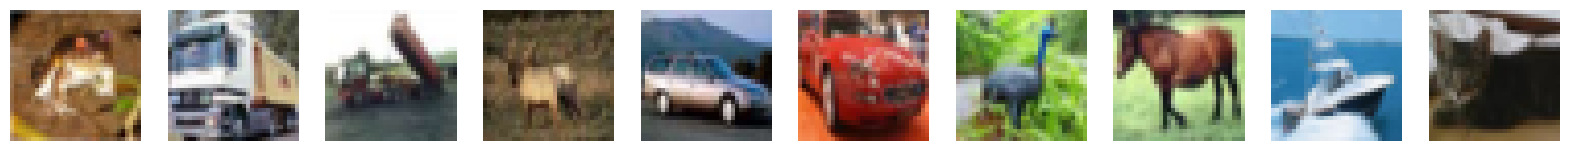

In [6]:
# Einige Bilder aus dem Trainingsset anzeigen
display(x_train)

## 2. Autoencoder aufbauen <a name="build"></a>

In [7]:
# Encoder
# v3: 4. Conv2D-Stufe ergänzt (32->64->128->256 Filter) plus BatchNormalization nach
# jeder Faltung, statt activation="relu" ohne Normalisierung direkt in Conv2D zu setzen
# -- mehr Kapazität und stabilere Gradienten (Changelog, Punkt 2).
encoder_input = layers.Input(
    shape=(IMAGE_SIZE, IMAGE_SIZE, CHANNELS), name="encoder_input"
)

x = layers.Conv2D(32, (3, 3), strides=2, padding="same")(encoder_input)
x = layers.BatchNormalization()(x)
x = layers.Activation("relu")(x)

x = layers.Conv2D(64, (3, 3), strides=2, padding="same")(x)
x = layers.BatchNormalization()(x)
x = layers.Activation("relu")(x)

x = layers.Conv2D(128, (3, 3), strides=2, padding="same")(x)
x = layers.BatchNormalization()(x)
x = layers.Activation("relu")(x)

x = layers.Conv2D(256, (3, 3), strides=2, padding="same")(x)
x = layers.BatchNormalization()(x)
x = layers.Activation("relu")(x)

shape_before_flattening = K.int_shape(x)[1:]  # wird vom Decoder gebraucht!

x = layers.Flatten()(x)
encoder_output = layers.Dense(EMBEDDING_DIM, name="encoder_output")(x)

encoder = models.Model(encoder_input, encoder_output, name="encoder")
encoder.summary()

Model: "encoder"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ encoder_input (InputLayer)      │ (None, 32, 32, 3)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d (Conv2D)                 │ (None, 16, 16, 32)     │           896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization             │ (None, 16, 16, 32)     │           128 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ activation (Activation)         │ (None, 16, 16, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 8, 8, 64)       │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_1           │ (None, 8, 8, 64)       │           256 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ activation_1 (Activation)       │ (None, 8, 8, 64)       │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_2 (Conv2D)               │ (None, 4, 4, 128)      │        73,856 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_2           │ (None, 4, 4, 128)      │           512 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ activation_2 (Activation)       │ (None, 4, 4, 128)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_3 (Conv2D)               │ (None, 2, 2, 256)      │       295,168 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_3           │ (None, 2, 2, 256)      │         1,024 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ activation_3 (Activation)       │ (None, 2, 2, 256)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten (Flatten)               │ (None, 1024)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ encoder_output (Dense)          │ (None, 32)             │        32,800 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 423,136 (1.61 MB)

 Trainable params: 422,176 (1.61 MB)

 Non-trainable params: 960 (3.75 KB)

In [8]:
# Decoder
# v3: spiegelt die 4. Stufe und die BatchNormalization des Encoders oben.
decoder_input = layers.Input(shape=(EMBEDDING_DIM,), name="decoder_input")
x = layers.Dense(int(np.prod(shape_before_flattening)))(decoder_input)
x = layers.Reshape(shape_before_flattening)(x)

x = layers.Conv2DTranspose(256, (3, 3), strides=2, padding="same")(x)
x = layers.BatchNormalization()(x)
x = layers.Activation("relu")(x)

x = layers.Conv2DTranspose(128, (3, 3), strides=2, padding="same")(x)
x = layers.BatchNormalization()(x)
x = layers.Activation("relu")(x)

x = layers.Conv2DTranspose(64, (3, 3), strides=2, padding="same")(x)
x = layers.BatchNormalization()(x)
x = layers.Activation("relu")(x)

x = layers.Conv2DTranspose(32, (3, 3), strides=2, padding="same")(x)
x = layers.BatchNormalization()(x)
x = layers.Activation("relu")(x)

decoder_output = layers.Conv2D(
    CHANNELS,
    (3, 3),
    strides=1,
    activation="sigmoid",
    padding="same",
    name="decoder_output",
)(x)

decoder = models.Model(decoder_input, decoder_output, name="decoder")
decoder.summary()

Model: "decoder"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ decoder_input (InputLayer)      │ (None, 32)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 1024)           │        33,792 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ reshape (Reshape)               │ (None, 2, 2, 256)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_transpose                │ (None, 4, 4, 256)      │       590,080 │
│ (Conv2DTranspose)               │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_4           │ (None, 4, 4, 256)      │         1,024 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ activation_4 (Activation)       │ (None, 4, 4, 256)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_transpose_1              │ (None, 8, 8, 128)      │       295,040 │
│ (Conv2DTranspose)               │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_5           │ (None, 8, 8, 128)      │           512 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ activation_5 (Activation)       │ (None, 8, 8, 128)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_transpose_2              │ (None, 16, 16, 64)     │        73,792 │
│ (Conv2DTranspose)               │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_6           │ (None, 16, 16, 64)     │           256 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ activation_6 (Activation)       │ (None, 16, 16, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_transpose_3              │ (None, 32, 32, 32)     │        18,464 │
│ (Conv2DTranspose)               │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_7           │ (None, 32, 32, 32)     │           128 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ activation_7 (Activation)       │ (None, 32, 32, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ decoder_output (Conv2D)         │ (None, 32, 32, 3)      │           867 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 1,013,955 (3.87 MB)

 Trainable params: 1,012,995 (3.86 MB)

 Non-trainable params: 960 (3.75 KB)

In [9]:
# Autoencoder
autoencoder = models.Model(
    encoder_input, decoder(encoder_output), name="autoencoder"
)  # decoder(encoder_output)
autoencoder.summary()

Model: "autoencoder"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ encoder_input (InputLayer)      │ (None, 32, 32, 3)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d (Conv2D)                 │ (None, 16, 16, 32)     │           896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization             │ (None, 16, 16, 32)     │           128 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ activation (Activation)         │ (None, 16, 16, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 8, 8, 64)       │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_1           │ (None, 8, 8, 64)       │           256 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ activation_1 (Activation)       │ (None, 8, 8, 64)       │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_2 (Conv2D)               │ (None, 4, 4, 128)      │        73,856 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_2           │ (None, 4, 4, 128)      │           512 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ activation_2 (Activation)       │ (None, 4, 4, 128)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_3 (Conv2D)               │ (None, 2, 2, 256)      │       295,168 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_3           │ (None, 2, 2, 256)      │         1,024 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ activation_3 (Activation)       │ (None, 2, 2, 256)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten (Flatten)               │ (None, 1024)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ encoder_output (Dense)          │ (None, 32)             │        32,800 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ decoder (Functional)            │ (None, 32, 32, 3)      │     1,013,955 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 1,437,091 (5.48 MB)

 Trainable params: 1,435,171 (5.47 MB)

 Non-trainable params: 1,920 (7.50 KB)

## 3. Autoencoder trainieren <a name="train"></a>

In [10]:
# Autoencoder kompilieren
# v3: Loss "binary_crossentropy" -> "mse" -- siehe Changelog, Punkt 3.
autoencoder.compile(optimizer="adam", loss="mse")

In [11]:
# Checkpoint zum Speichern des Modells anlegen
# v3: monitor "loss" -> "val_loss" (das Original überwachte den Trainings-Loss,
# nicht den zurückgehaltenen Split), dazu EarlyStopping/ReduceLROnPlateau, damit das
# Training läuft, bis es sich nicht mehr verbessert -- siehe Changelog, Punkt 4.
model_checkpoint_callback = callbacks.ModelCheckpoint(
    filepath="./checkpoint_v3.keras",
    save_weights_only=False,
    save_freq="epoch",
    monitor="val_loss",
    mode="min",
    save_best_only=True,
    verbose=0,
)
tensorboard_callback = callbacks.TensorBoard(log_dir="./logs_v3")
early_stopping_callback = callbacks.EarlyStopping(
    monitor="val_loss", patience=5, restore_best_weights=True, verbose=1
)
reduce_lr_callback = callbacks.ReduceLROnPlateau(
    monitor="val_loss", factor=0.5, patience=3, min_lr=1e-5, verbose=1
)

In [12]:
if TRAIN_MODEL:
    autoencoder.fit(
        x_train,
        x_train,
        epochs=EPOCHS,
        batch_size=BATCH_SIZE,
        shuffle=True,
        validation_data=(x_test, x_test),
        callbacks=[
            model_checkpoint_callback,
            tensorboard_callback,
            early_stopping_callback,
            reduce_lr_callback,
        ],
    )
else:
    autoencoder.set_weights(models.load_model("./models/autoencoder_v3.keras", compile=False).get_weights())

In [13]:
if TRAIN_MODEL:
    # Finale Modelle speichern
    # v3: mit _v3-Suffix gespeichert, damit dieser Lauf die Artefakte des Original- bzw.
    # Bugfix-Notebooks nicht überschreibt -- siehe Changelog, Punkt 7.
    from pathlib import Path
    Path("./models").mkdir(parents=True, exist_ok=True)
    autoencoder.save("./models/autoencoder_v3.keras")
    encoder.save("./models/encoder_v3.keras")
    decoder.save("./models/decoder_v3.keras")

## 4. Rekonstruieren mit dem Autoencoder <a name="reconstruct"></a>

In [14]:
n_to_predict = 5000
example_images = x_test[:n_to_predict]
example_labels = y_test[:n_to_predict]

  1/157 ━━━━━━━━━━━━━━━━━━━━ 55s 358ms/step

  5/157 ━━━━━━━━━━━━━━━━━━━━ 2s 18ms/step  

  9/157 ━━━━━━━━━━━━━━━━━━━━ 2s 16ms/step

 12/157 ━━━━━━━━━━━━━━━━━━━━ 2s 16ms/step

 16/157 ━━━━━━━━━━━━━━━━━━━━ 2s 16ms/step

 20/157 ━━━━━━━━━━━━━━━━━━━━ 2s 16ms/step

... (34 outputs left out)

153/157 ━━━━━━━━━━━━━━━━━━━━ 0s 16ms/step

157/157 ━━━━━━━━━━━━━━━━━━━━ 0s 18ms/step

157/157 ━━━━━━━━━━━━━━━━━━━━ 3s 18ms/step


Example real images


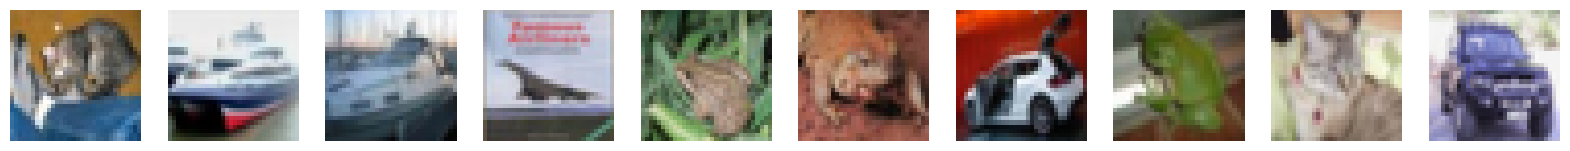

Reconstructions


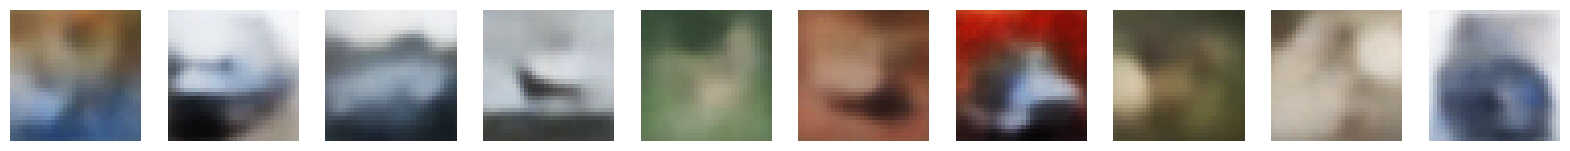

In [15]:
predictions = autoencoder.predict(example_images)

print("Example real images")
display(example_images)
print("Reconstructions")
display(predictions)

## 5. Einbetten mit dem Encoder <a name="encode"></a>

In [16]:
# Beispielbilder kodieren
embeddings = encoder.predict(example_images)

  1/157 ━━━━━━━━━━━━━━━━━━━━ 23s 148ms/step

 15/157 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step   

 28/157 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step

 42/157 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step

 54/157 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step

 65/157 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step

... (6 outputs left out)

143/157 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step

150/157 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step

157/157 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step

157/157 ━━━━━━━━━━━━━━━━━━━━ 1s 6ms/step


In [17]:
# Einige Beispiele der Embeddings
# v3: jetzt 32-dimensionale statt 2-dimensionale Vektoren -- siehe Changelog, Punkt 1.
print(embeddings[:10])

[[  1.1081684   -2.8916364    1.6635581   -2.952464     4.240686
   -4.385285     0.11246578  -0.04882881  -0.30696553  -1.9435709
    1.5866393   -1.6054747   -6.150759    -4.704626     0.59072506
    0.52070594  -1.5022907   -2.6316257   -4.94923      0.61051655
   -0.03288448  -3.393629    -0.5160477    2.1340547   -5.383945
    0.6636626    0.48438418  -2.1092622   -3.120577     1.4749186
   -4.3006535    4.395588  ]
 [  5.817073     4.4870863   -7.0403605   -2.198111    -9.433668
    1.9362351    0.26141137   3.6709723    3.397679     0.667414
   -1.6983112   -2.7127075   -2.922784    -1.5546372    4.8140817
    5.524232     5.301408    -4.6738744    8.372733     8.582737
    5.8104987    5.8015776   -2.7001612   -2.8636281   -5.040581
    1.059008     2.9182622   -1.8150313    4.862801     6.815899
   -7.1397634   -4.5809116 ]
 [  5.5048404    2.1712365   -0.47053897  -7.954938    -7.000861
   -0.61324733  -4.269409    -3.640102    -2.8693376   -3.6148407
    0.07456265   0.57716

### 5a. Einen höherdimensionalen latenten Raum visualisieren

Mit `EMBEDDING_DIM = 32` lässt sich das rohe Embedding nicht mehr direkt als Streudiagramm darstellen; zwei beliebige von 32 Achsen zu plotten, wäre genauso wenig aussagekräftig wie zuvor. Stattdessen projizieren wir das gesamte 32-dimensionale Embedding **nur zur Visualisierung** auf 2D, mit zwei Standardverfahren:

- **PCA**: eine schnelle, lineare Projektion auf die 2 Richtungen mit der größten Varianz. Gut als Plausibilitätsprüfung, kann aber nichtlineare Clusterstrukturen verbergen.
- **t-SNE**: eine nichtlineare Projektion, die gezielt lokale Nachbarschaften zu erhalten versucht. Sie zeigt tatsächlich vorhandene Clusterstrukturen im Embedding deshalb viel besser, ist aber langsamer und erhält globale Abstände nicht.

Überlappen sich die Klassen selbst in der t-SNE-Projektion stark, ist das ein deutliches Zeichen, dass das Embedding selbst die Klassen schlecht trennt (und nicht nur ein Artefakt des 2D-Plots).

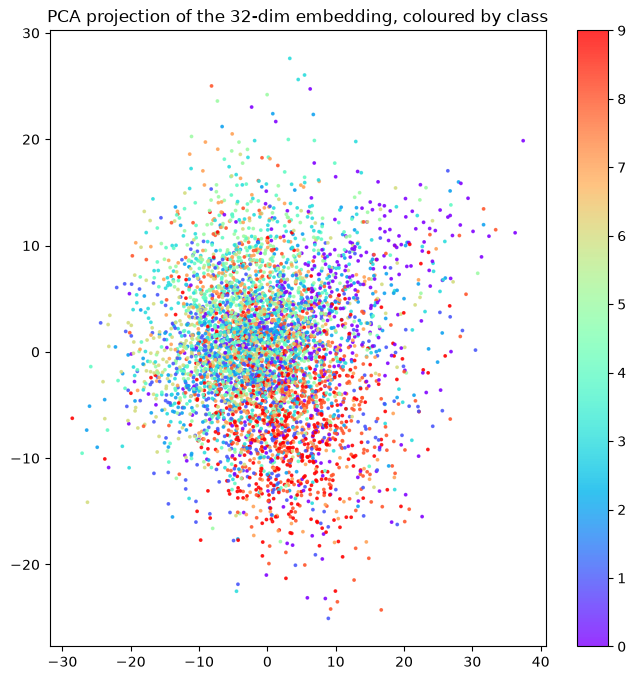

In [18]:
# PCA-Projektion des Embeddings, nach Klasse eingefärbt
pca = PCA(n_components=2)
embeddings_pca = pca.fit_transform(embeddings)

figsize = 8
plt.figure(figsize=(figsize, figsize))
scatter = plt.scatter(
    embeddings_pca[:, 0],
    embeddings_pca[:, 1],
    cmap="rainbow",
    c=example_labels,
    alpha=0.8,
    s=3,
)
plt.colorbar(scatter)
plt.title("PCA projection of the 32-dim embedding, coloured by class")
plt.show()

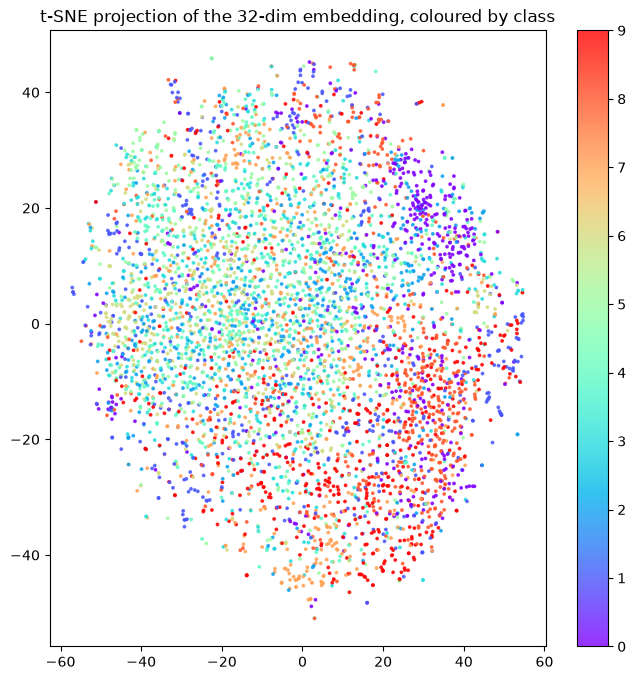

In [19]:
# t-SNE-Projektion des Embeddings, nach Klasse eingefärbt
tsne = TSNE(n_components=2, init="pca", perplexity=30, random_state=42)
embeddings_tsne = tsne.fit_transform(embeddings)

figsize = 8
plt.figure(figsize=(figsize, figsize))
scatter = plt.scatter(
    embeddings_tsne[:, 0],
    embeddings_tsne[:, 1],
    cmap="rainbow",
    c=example_labels,
    alpha=0.8,
    s=3,
)
plt.colorbar(scatter)
plt.title("t-SNE projection of the 32-dim embedding, coloured by class")
plt.show()

### 5b. Klassentrennung quantifizieren: eine k-NN-Probe

Statt die Trennung nach Augenmaß zu beurteilen, ist es aussagekräftiger, das Embedding als Merkmale für einen einfachen Klassifikator zu verwenden und die Genauigkeit auf zurückgehaltenen Daten zu messen. Trägt das Embedding tatsächlich Klasseninformation, sollte selbst ein einfacher k-NN-Klassifikator das Raten (10 % bei 10 ausgeglichenen Klassen) deutlich schlagen. Schlägt er es kaum, ist das Embedding nicht klassentrennend, wie auch immer es im 2D-Plot aussieht, und kein Plot ändert daran etwas. Ist Klassentrennung tatsächlich das Ziel, muss sich das Trainingsziel selbst ändern (z. B. durch einen überwachten oder kontrastiven Loss).

Wir vergleichen zwei Merkmalssätze auf demselben Train/Test-Split der 5000 Beispielbilder: rohe, flach gemachte Pixel (3072 Dimensionen, keine gelernte Kompression) und das 32-dimensionale Embedding des Autoencoders.

In [20]:
labels_flat = example_labels.ravel()
pixels_flat = example_images.reshape(len(example_images), -1)

(
    emb_train, emb_test,
    pix_train, pix_test,
    y_train_knn, y_test_knn,
) = train_test_split(
    embeddings,
    pixels_flat,
    labels_flat,
    test_size=0.2,
    random_state=42,
    stratify=labels_flat,
)

knn_embedding = KNeighborsClassifier(n_neighbors=5).fit(emb_train, y_train_knn)
acc_embedding = accuracy_score(y_test_knn, knn_embedding.predict(emb_test))

knn_pixels = KNeighborsClassifier(n_neighbors=5).fit(pix_train, y_train_knn)
acc_pixels = accuracy_score(y_test_knn, knn_pixels.predict(pix_test))

print(f"k-NN accuracy on raw pixels:          {acc_pixels:.3f}")
print(f"k-NN accuracy on 32-dim AE embedding: {acc_embedding:.3f}")
print(f"random-guess baseline (10 classes):   0.100")

k-NN accuracy on raw pixels:          0.269
k-NN accuracy on 32-dim AE embedding: 0.338
random-guess baseline (10 classes):   0.100


### Fazit: was die Klassentrennung tatsächlich beeinflusst und was nicht

Die Änderungen in diesem Notebook (größerer Engpass, mehr Kapazität, ein passenderer Loss, ein sauber überwachter Trainingsablauf und ehrliche 2D-Projektionen statt eines erzwungenen 2D-Engpasses) sollten das Embedding tatsächlich verbessern, auch für die Rekonstruktion, und die k-NN-Probe oben sollte messbar höher liegen, als es ein 2-dimensionaler Engpass erreichen könnte. Nichts davon ändert aber die grundlegende Tatsache, dass **einem einfachen Autoencoder nie gesagt wird, was eine Klasse ist**. Ist gute Klassentrennung das eigentliche Ziel, sind die nächsten Schritte, ungefähr nach steigendem Aufwand und Nutzen:

1. **Überwachter oder teilüberwachter Autoencoder**: einen kleinen Klassifikationskopf auf das Embedding setzen und gemeinsam mit einem zusätzlichen Kreuzentropie-Loss gegen `y_train`/`y_test` trainieren. Damit wird das Embedding direkt auf Klassentrennung optimiert und nicht nur darauf, für die Rekonstruktion auszureichen.
2. **Kontrastives bzw. selbstüberwachtes Lernen** (z. B. im Stil von SimCLR): zieht augmentierte Ansichten *desselben* Bildes zusammen und drückt verschiedene Bilder auseinander, ganz ohne Rekonstruktion. Das ist der moderne Standard für Embeddings, die nach semantischem Inhalt clustern.
3. **Direkt einen überwachten CNN-Klassifikator** auf CIFAR-10 trainieren, falls die Klassifikationsgenauigkeit das eigentliche Endziel ist, und den Autoencoder-Engpass ganz weglassen. Er wird jedes aus einem Autoencoder gewonnene Merkmal übertreffen, weil nur diese Option tatsächlich auf dieses Ziel optimiert ist.

Siehe auch `autoencoder_on_CIFAR-10_v2_vae.ipynb` in diesem Ordner für die VAE-Variante. Der KL-Term eines VAE macht den latenten Raum glatter und kontinuierlicher (besser zum *Generieren* neuer Bilder). Das ist eine andere Eigenschaft als Klassentrennung, und auch davon ist nicht zu erwarten, dass sie den Klumpen auflöst.